<a href="https://colab.research.google.com/github/catarina1532/project-template/blob/main/EucaNutri_Preliminary_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EucaNutri — Preliminary Exploratory Data Analysis (Data Science)

**Purpose.** Reproducible preliminary assessment of the RAIZ monitoring data and the separately extracted ERA5-Land climate indicators. This notebook supports the data-acquisition/management workshop and documents both findings and outstanding validation tasks.

**Important scope notes**
- 144 is the number of monitoring visits/ID-year records; 190 is the number of leaf records. These are different observation levels.
- The climate CSV contains 144 location-year rows. Matching all 144 available RAIZ visit-year records does **not** mean that every location has a complete 2019–2025 time series.
- ERA5-Land data are extracted but are not yet integrated into the team's Supabase database or GeoPackage.
- Climate hydrological indicators require physical validation before modelling.

Run the notebook from top to bottom. When prompted, upload `eucanutri (3).zip` (or the current project ZIP containing `eucanutri/eucanutri_visualizacao.xlsx` and `eucanutri/clima_indicadores.csv`).

## 1. Load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile, io, sqlite3
from google.colab import files
from IPython.display import display

uploaded = files.upload()
zip_name = next(iter(uploaded))
zip_file = zipfile.ZipFile(io.BytesIO(uploaded[zip_name]))

excel_bytes = zip_file.read("eucanutri/eucanutri_visualizacao.xlsx")
folhas = pd.read_excel(io.BytesIO(excel_bytes), sheet_name="folha_tabela")
solo = pd.read_excel(io.BytesIO(excel_bytes), sheet_name="solo_tabela")
diagnose = pd.read_excel(io.BytesIO(excel_bytes), sheet_name="diagnose_visual")
observacoes = pd.read_excel(io.BytesIO(excel_bytes), sheet_name="observacoes")
referencias = pd.read_excel(io.BytesIO(excel_bytes), sheet_name="referencia_classes")
clima = pd.read_csv(io.BytesIO(zip_file.read("eucanutri/clima_indicadores.csv")), sep=";")

tabelas = {
    "Folhas": folhas, "Solo": solo, "Diagnóstico visual": diagnose,
    "Observações": observacoes, "Referências": referencias, "Clima": clima
}
for nome, df in tabelas.items():
    print(f"{nome}: {len(df)} registos | {len(df.columns)} variáveis")

Saving eucanutri (3).zip to eucanutri (3).zip
Folhas: 190 registos | 25 variáveis
Solo: 144 registos | 28 variáveis
Diagnóstico visual: 154 registos | 11 variáveis
Observações: 144 registos | 10 variáveis
Referências: 145 registos | 8 variáveis
Clima: 144 registos | 14 variáveis


## 2. Data quality and coverage

This section checks full-row duplicates, missing values, unique identifiers and cross-source coverage. Full-row duplicates and duplicate operational keys are different checks; both are reported.

In [2]:
# Overall table audit — includes the nutritional reference table
resumo = []
for nome, df in tabelas.items():
    id_col = "localizacao_id" if "localizacao_id" in df.columns else ("id" if "id" in df.columns else None)
    resumo.append({
        "Tabela": nome, "Registos": len(df), "Variáveis": len(df.columns),
        "Linhas duplicadas": int(df.duplicated().sum()),
        "Valores omissos": int(df.isna().sum().sum()),
        "Coluna ID": id_col or "Não aplicável",
        "IDs únicos": int(df[id_col].nunique()) if id_col else np.nan
    })
display(pd.DataFrame(resumo))

# Missing values by variable
for nome, df in tabelas.items():
    missing = pd.DataFrame({"Omissos": df.isna().sum(), "Percentagem (%)": (100*df.isna().mean()).round(1)})
    missing = missing[missing.Omissos > 0].sort_values("Percentagem (%)", ascending=False)
    if not missing.empty:
        print("\n" + nome.upper())
        display(missing)

# Operational duplicate-key checks — key definitions should be confirmed against the data dictionary
key_checks = {
    "Folhas (id, ano, amostra)": (folhas, ["id", "ano", "amostra"]),
    "Solo (id, ano, amostra)": (solo, ["id", "ano", "amostra"]),
    "Diagnóstico (id, ano, ficha)": (diagnose, ["id", "ano", "ficha"]),
    "Observações (id, ano)": (observacoes, ["id", "ano"]),
    "Clima (localizacao_id, ano)": (clima, ["localizacao_id", "ano"])
}
print("DUPLICADOS NAS CHAVES OPERACIONAIS")
for label, (df, cols) in key_checks.items():
    print(f"{label}: {int(df.duplicated(cols).sum())}")

,Tabela,Registos,Variáveis,Linhas duplicadas,Valores omissos,Coluna ID,IDs únicos
0,Folhas,190,25,0,511,id,143.0
1,Solo,144,28,0,916,id,143.0
2,Diagnóstico visual,154,11,0,235,id,144.0
3,Observações,144,10,0,20,id,144.0
4,Referências,145,8,0,60,Não aplicável,NaN
5,Clima,144,14,0,21,localizacao_id,144.0



FOLHAS


,Omissos,Percentagem (%)
C,166,87.4
parcela,162,85.3
zona_homogenea,119,62.6
S,64,33.7



SOLO


,Omissos,Percentagem (%)
zona_homogenea,124,86.1
textura,124,86.1
terra_fina_pct,123,85.4
N,102,70.8
ce_dsm,102,70.8
classe_B,80,55.6
B,60,41.7
Mn,40,27.8
Cu,40,27.8
Fe,40,27.8



DIAGNÓSTICO VISUAL


... (4 outputs left out)

,Omissos,Percentagem (%)
minimo_incl,30,20.7
maximo_excl,30,20.7



CLIMA


,Omissos,Percentagem (%)
temp_media_anual,3,2.1
temp_max_absoluta,3,2.1
temp_min_absoluta,3,2.1
humidade_solo_l1,3,2.1
humidade_solo_l2,3,2.1
amplitude_termica_anual,3,2.1
gradiente_humidade_solo,3,2.1


DUPLICADOS NAS CHAVES OPERACIONAIS
Folhas (id, ano, amostra): 0
Solo (id, ano, amostra): 0
Diagnóstico (id, ano, ficha): 0
Observações (id, ano): 0
Clima (localizacao_id, ano): 0


In [3]:
# Compare monitoring IDs across core sources — explicitly identify IDs missing from each source
ids_obs = set(observacoes["id"].dropna())
ids_folhas = set(folhas["id"].dropna())
ids_solo = set(solo["id"].dropna())
ids_diag = set(diagnose["id"].dropna())

print("IDs sem amostras foliares:", sorted(ids_obs - ids_folhas))
print("IDs sem análises de solo:", sorted(ids_obs - ids_solo))
print("IDs sem diagnóstico visual:", sorted(ids_obs - ids_diag))
ids_completos = ids_obs & ids_folhas & ids_solo & ids_diag
print("Visitas com folhas, solo e diagnóstico visual:", len(ids_completos))
print("Visitas sem pelo menos uma destas fontes:", len(ids_obs - ids_completos))

IDs sem amostras foliares: [32]
IDs sem análises de solo: [32]
IDs sem diagnóstico visual: []
Visitas com folhas, solo e diagnóstico visual: 143
Visitas sem pelo menos uma destas fontes: 1


**Interpretation.** The current audit identifies ID 32 as having visual diagnosis but no corresponding leaf or soil records. The 143 complete IDs refer to the intersection of IDs across the three sources; they do not imply that every individual sample row is one-to-one across tables.

## 3. Temporal and regional distribution

VISITAS POR ANO


,Número de visitas
ano,
2019,20
2020,21
2021,20
2022,20
2023,22
2024,20
2025,21


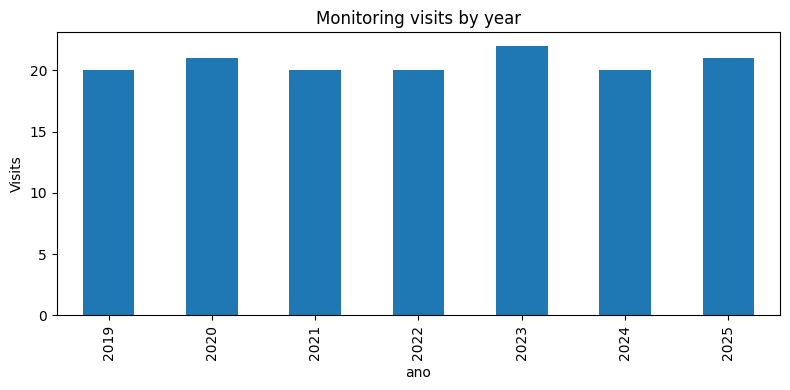

VISITAS POR REGIÃO


,Número de visitas
regiao,
North,37
South,37
Interior,36
Tagus Valley and Sado,34


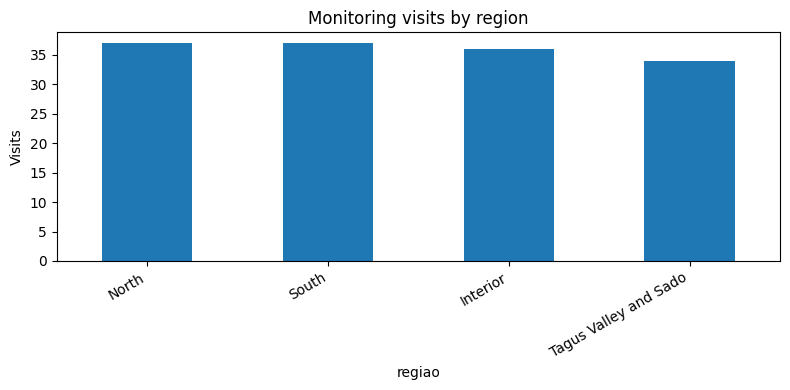

,count,mean,std,min,25%,50%,75%,max
idade_anos,144.0,1.899,0.383,1.20,1.598,2.000,2.010,3.10
area_ha,144.0,24.215,25.469,1.20,6.692,12.800,32.758,151.20
acm,144.0,10.672,3.734,2.98,8.090,10.225,12.320,25.88
rotacao,144.0,1.667,0.853,1.00,1.000,1.000,2.000,5.00


In [4]:
print("VISITAS POR ANO")
visitas_ano = observacoes.groupby("ano")["id"].nunique().sort_index()
display(visitas_ano.rename("Número de visitas").to_frame())
visitas_ano.plot(kind="bar", figsize=(8,4), title="Monitoring visits by year", ylabel="Visits")
plt.tight_layout(); plt.show()

print("VISITAS POR REGIÃO")
visitas_regiao = observacoes.groupby("regiao")["id"].nunique().sort_values(ascending=False)
display(visitas_regiao.rename("Número de visitas").to_frame())
visitas_regiao.plot(kind="bar", figsize=(8,4), title="Monitoring visits by region", ylabel="Visits")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

cols_desc = [c for c in ["idade_anos", "area_ha", "acm", "rotacao"] if c in observacoes.columns]
display(observacoes[cols_desc].describe().T.round(3))

## 4. Leaf nutritional status

,N,Média,Desvio padrão,Mínimo,Q1,Mediana,Q3,Máximo
N,190.0,1.520,0.426,0.64,1.30,1.53,1.800,2.60
P,190.0,0.114,0.071,0.06,0.07,0.10,0.130,0.56
K,190.0,0.628,0.172,0.15,0.51,0.60,0.700,1.24
B,190.0,24.537,13.468,4.00,18.00,21.85,28.175,122.40



 classe_N


,Amostras
Classe,
Média,67
Baixa,58
Muito baixa,38
Alta,27



 classe_P


,Amostras
Classe,
Baixa,90
Média,64
Alta,28
Muito alta,8



 classe_K


,Amostras
Classe,
Média,99
Alta,55
Baixa,31
Muito baixa,5



 classe_B


,Amostras
Classe,
Média,101
Baixa,67
Alta,16
Muito baixa,4
Muito alta,2


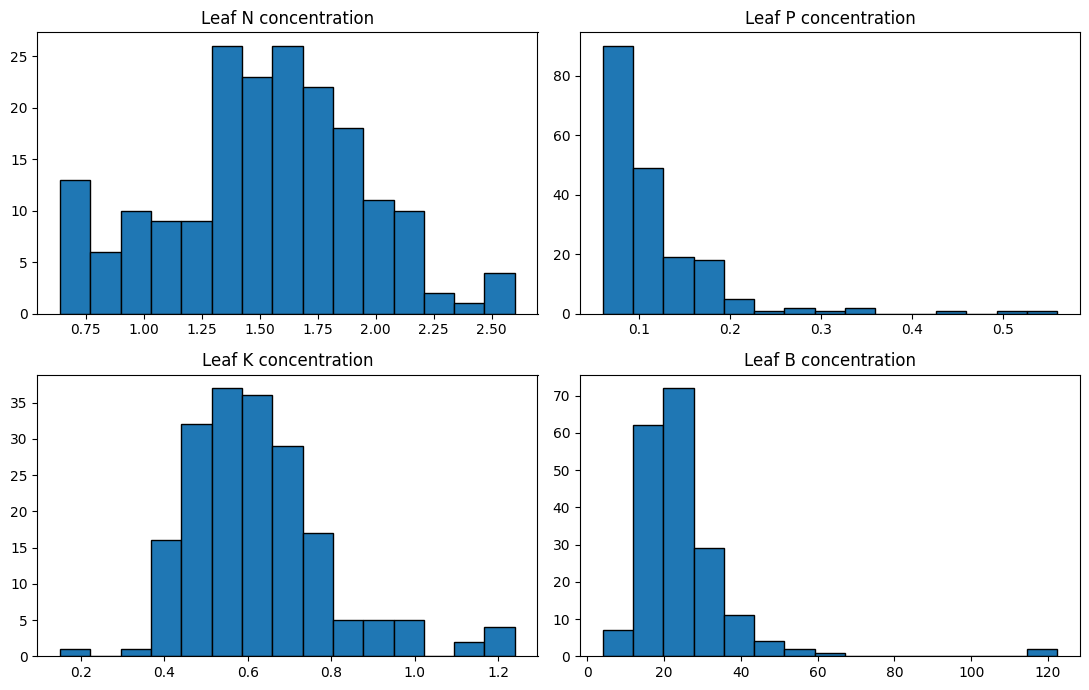

In [5]:
nutrientes = ["N", "P", "K", "B"]
for col in nutrientes:
    folhas[col] = pd.to_numeric(folhas[col], errors="coerce")

# Mean, standard deviation, minimum, quartiles, median and maximum
stats_folhas = folhas[nutrientes].describe().T.rename(columns={
    "count":"N", "mean":"Média", "std":"Desvio padrão", "min":"Mínimo",
    "25%":"Q1", "50%":"Mediana", "75%":"Q3", "max":"Máximo"
})
display(stats_folhas.round(3))

# Available nutritional classes
for col in ["classe_N", "classe_P", "classe_K", "classe_B"]:
    if col in folhas.columns:
        print("\n", col)
        display(folhas[col].value_counts(dropna=False).rename_axis("Classe").to_frame("Amostras"))

fig, axes = plt.subplots(2, 2, figsize=(11,7))
for ax, col in zip(axes.flat, nutrientes):
    ax.hist(folhas[col].dropna(), bins=15, edgecolor="black")
    ax.set_title(f"Leaf {col} concentration")
plt.tight_layout(); plt.show()

**Interpretation.** The leaf dataset contains 190 records. The mean exceeds the median for each of N, P, K and B, suggesting right-skewness. The high maximum values for P and especially B should be checked against source records and units; they should not automatically be removed as errors. Nutritional classes describe measured concentrations relative to the supplied reference thresholds and are not, by themselves, proof of a diagnosed tree deficiency.

## 5. Leaf–soil relationships, including the separate soil nitrogen analysis

In [6]:
# Aggregate leaf measurements to monitoring visit level for the broad exploratory merge
folhas_visita = folhas.groupby(["id", "ano"], as_index=False)[nutrientes].mean()

solo_vars = ["ph_h2o", "mo_pct", "P", "K", "Ca", "Mg", "B", "gsb_pct"]
for col in solo_vars + ["N"]:
    solo[col] = pd.to_numeric(solo[col], errors="coerce")

# Aggregate soil records by visit and rename soil nutrient fields to avoid ambiguous column names
solo_agregado = solo.groupby(["id", "ano"], as_index=False)[solo_vars + ["N"]].mean()
solo_agregado = solo_agregado.rename(columns={c: f"solo_{c}" for c in ["P", "K", "B", "N"]})
folha_solo = folhas_visita.merge(solo_agregado, on=["id", "ano"], how="inner", validate="one_to_one")

corr_vars = nutrientes + ["ph_h2o", "mo_pct", "solo_P", "solo_K", "Ca", "Mg", "solo_B", "gsb_pct"]
corr_data = folha_solo[corr_vars]
display(corr_data.corr().round(2))
display(corr_data.notna().astype(int).T.dot(corr_data.notna().astype(int)))

# Separate leaf N vs soil N analysis — small coverage must be made explicit
pares_N = folha_solo.dropna(subset=["N", "solo_N"]).copy()
print("Visitas integradas:", len(folha_solo))
print("Pares completos N foliar / N solo:", len(pares_N))
print("Visitas sem N do solo disponível:", folha_solo["solo_N"].isna().sum())
print("Correlação de Pearson N foliar / N solo:", round(pares_N["N"].corr(pares_N["solo_N"]), 3))
display(pares_N[["N", "solo_N"]].describe().round(3))

,N,P,K,B,ph_h2o,mo_pct,solo_P,solo_K,Ca,Mg,solo_B,gsb_pct
N,1.00,0.23,0.25,-0.03,-0.23,0.27,0.02,-0.06,-0.03,-0.10,0.22,-0.15
P,0.23,1.00,0.19,0.09,0.13,-0.05,0.04,0.02,0.09,0.20,0.21,0.06
K,0.25,0.19,1.00,0.13,0.08,-0.16,-0.02,0.16,0.09,-0.01,0.02,0.16
B,-0.03,0.09,0.13,1.00,0.22,-0.14,-0.24,0.21,0.01,0.01,0.09,0.12
ph_h2o,-0.23,0.13,0.08,0.22,1.00,-0.55,-0.35,0.19,0.38,0.27,-0.05,0.63
mo_pct,0.27,-0.05,-0.16,-0.14,-0.55,1.00,0.13,-0.05,-0.09,-0.26,0.55,-0.52
solo_P,0.02,0.04,-0.02,-0.24,-0.35,0.13,1.00,0.14,0.19,0.11,0.04,0.13
solo_K,-0.06,0.02,0.16,0.21,0.19,-0.05,0.14,1.00,0.41,0.42,0.38,0.37
Ca,-0.03,0.09,0.09,0.01,0.38,-0.09,0.19,0.41,1.00,0.58,0.18,0.66
Mg,-0.10,0.20,-0.01,0.01,0.27,-0.26,0.11,0.42,0.58,1.00,-0.08,0.55


,N,P,K,B,ph_h2o,mo_pct,solo_P,solo_K,Ca,Mg,solo_B,gsb_pct
N,143,143,143,143,143,143,108,141,141,130,63,123
P,143,143,143,143,143,143,108,141,141,130,63,123
K,143,143,143,143,143,143,108,141,141,130,63,123
B,143,143,143,143,143,143,108,141,141,130,63,123
ph_h2o,143,143,143,143,143,143,108,141,141,130,63,123
mo_pct,143,143,143,143,143,143,108,141,141,130,63,123
solo_P,108,108,108,108,108,108,108,106,107,99,53,88
solo_K,141,141,141,141,141,141,106,141,139,130,63,122
Ca,141,141,141,141,141,141,107,139,141,130,62,122
Mg,130,130,130,130,130,130,99,130,130,130,60,114


Visitas integradas: 143
Pares completos N foliar / N solo: 41
Visitas sem N do solo disponível: 102
Correlação de Pearson N foliar / N solo: 0.519


,N,solo_N
count,41.000,41.000
mean,1.713,0.165
std,0.388,0.105
min,1.000,0.050
25%,1.450,0.050
50%,1.600,0.140
75%,2.000,0.250
max,2.600,0.400


**Interpretation — important limitation.** The separate nitrogen result in the current analysis is **41 complete pairs** and Pearson **r = 0.519**. This is a moderate positive linear association in a limited subset, not evidence of causality and not representative automatically of all 143 integrated visits. Soil N is missing for 102 of the 143 visits. The broader leaf–soil matrix generally shows weak linear relationships; pair counts vary by variable.

## 6. Visual diagnosis

In [7]:
# CS = symptomatic; SS = asymptomatic, according to the workbook data dictionary
nut_sym = diagnose["desordem_nutricional"].eq("CS")
non_nut_sym = diagnose["desordem_nao_nutricional"].eq("CS")
print("Records with nutritional symptoms:", int(nut_sym.sum()))
print("Records with non-nutritional symptoms:", int(non_nut_sym.sum()))
print("Records with both nutritional and non-nutritional symptoms:", int((nut_sym & non_nut_sym).sum()))
display(pd.crosstab(diagnose["desordem_nutricional"], diagnose["desordem_nao_nutricional"], dropna=False))

Records with nutritional symptoms: 53
Records with non-nutritional symptoms: 124
Records with both nutritional and non-nutritional symptoms: 47


desordem_nao_nutricional,CS,SS,NaN
desordem_nutricional,,,
CS,47,6,0
SS,76,18,0
NaN,1,0,6


## 7. Nutrition, stand age, region and productivity

Médias dos nutrientes por região


,N,P,K,B
regiao,,,,
Interior,1.363,0.106,0.629,27.769
North,1.783,0.113,0.583,19.138
South,1.451,0.110,0.634,25.169
Tagus Valley and Sado,1.496,0.108,0.635,21.943


Correlações entre nutrientes, idade e ACM


,N,P,K,B,idade_anos,acm
N,1.00,0.23,0.25,-0.03,-0.19,0.27
P,0.23,1.00,0.19,0.09,-0.10,-0.06
K,0.25,0.19,1.00,0.13,-0.23,-0.08
B,-0.03,0.09,0.13,1.00,0.13,-0.08
idade_anos,-0.19,-0.10,-0.23,0.13,1.00,-0.14
acm,0.27,-0.06,-0.08,-0.08,-0.14,1.00


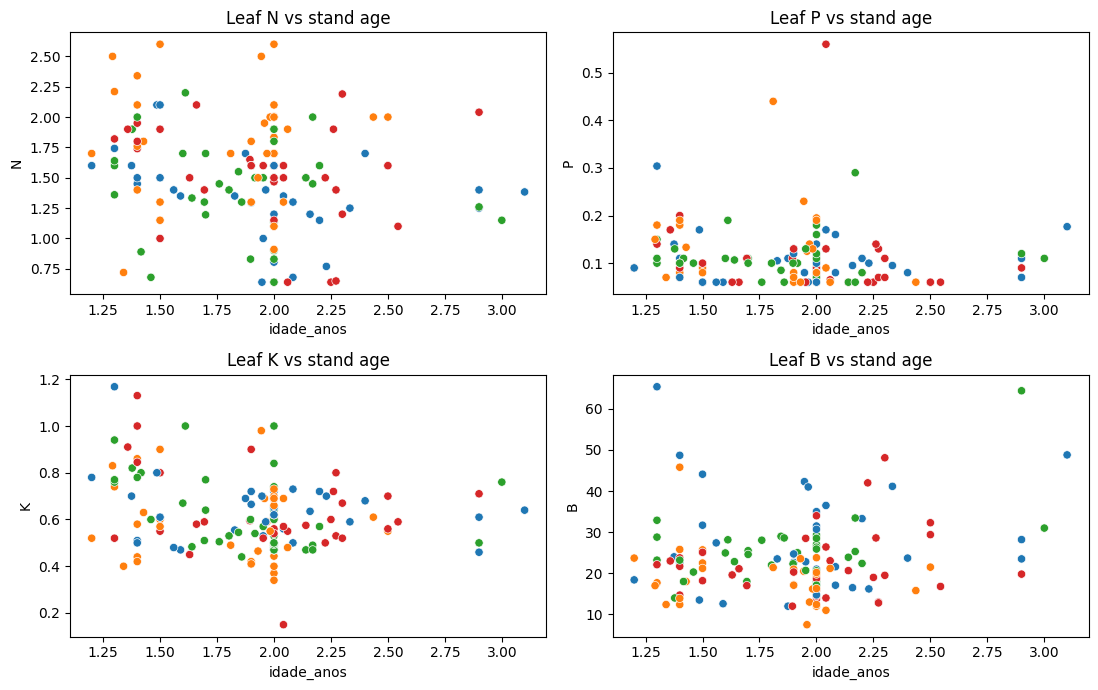

In [8]:
dados_prod = folhas_visita.merge(
    observacoes[["id", "ano", "idade_anos", "acm", "area_ha", "regiao", "regime"]],
    on=["id", "ano"], how="inner", validate="one_to_one"
)
print("Médias dos nutrientes por região")
display(dados_prod.groupby("regiao")[nutrientes].mean().round(3))
print("Correlações entre nutrientes, idade e ACM")
display(dados_prod[nutrientes + ["idade_anos", "acm"]].corr().round(2))

fig, axes = plt.subplots(2, 2, figsize=(11,7))
for ax, col in zip(axes.flat, nutrientes):
    sns.scatterplot(data=dados_prod, x="idade_anos", y=col, hue="regiao", ax=ax, legend=False)
    ax.set_title(f"Leaf {col} vs stand age")
plt.tight_layout(); plt.show()

**Interpretation.** Regional differences and correlations with age/productivity are exploratory associations only. They may justify retaining region, age, rotation/regime and stand descriptors as candidate contextual predictors, subject to data completeness and the final modelling target. They do not establish causal effects.

## 8. ERA5-Land climate data: coverage, missingness and validation

In [9]:
clima_vars = ["temp_media_anual", "temp_max_absoluta", "temp_min_absoluta", "precip_total_anual",
              "evap_potencial_anual", "humidade_solo_l1", "humidade_solo_l2",
              "balanco_hidrico_anual", "amplitude_termica_anual", "gradiente_humidade_solo"]
print("Climate dataset dimensions:", clima.shape)
print("Unique locations:", clima["localizacao_id"].nunique())
print("Unique years:", sorted(clima["ano"].dropna().unique().tolist()))
print("Missing cells:", int(clima.isna().sum().sum()))
display(clima[clima_vars].describe().T.round(3))
missing_clima = clima.isna().sum().rename("Omissos").to_frame()
missing_clima["Percentagem (%)"] = (100*clima.isna().mean()).round(1)
display(missing_clima[missing_clima.Omissos > 0])

# Check duplicate climate location-year keys
print("Duplicados (localizacao_id, ano):", int(clima.duplicated(["localizacao_id", "ano"]).sum()))

# Match RAIZ visit-year records to climate location-year records
raiz_keys = observacoes[["id", "ano"]].drop_duplicates().rename(columns={"id":"localizacao_id"})
clima_keys = clima[["localizacao_id", "ano"]].drop_duplicates()
check = raiz_keys.merge(clima_keys, on=["localizacao_id", "ano"], how="outer", indicator=True)
print("RAIZ visit-year pairs:", len(raiz_keys))
print("Climate location-year pairs:", len(clima_keys))
print("Matched pairs:", int((check["_merge"] == "both").sum()))
print("RAIZ pairs without climate:", int((check["_merge"] == "left_only").sum()))
print("Climate pairs without RAIZ:", int((check["_merge"] == "right_only").sum()))

# Explicitly show whether each location has a full 2019–2025 series
coverage = clima.groupby("localizacao_id")["ano"].nunique()
print("Locations with all 7 years:", int((coverage == 7).sum()), "of", int(coverage.size))
print("Year counts in climate file:")
display(clima.groupby("ano")["localizacao_id"].nunique().rename("Locations").to_frame())

Climate dataset dimensions: (144, 14)
Unique locations: 144
Unique years: [2019, 2020, 2021, 2022, 2023, 2024, 2025]
Missing cells: 21


,count,mean,std,min,25%,50%,75%,max
temp_media_anual,141.0,16.019,1.214,12.810,15.160,16.300,16.980,18.010
temp_max_absoluta,141.0,36.529,2.692,29.400,34.390,36.620,38.580,41.980
temp_min_absoluta,141.0,0.261,2.052,-4.510,-1.240,0.180,1.540,6.870
precip_total_anual,144.0,2031.229,1031.163,0.000,1256.800,1736.300,2645.000,5012.800
evap_potencial_anual,144.0,4420.464,879.084,0.000,3968.725,4417.350,5031.300,6163.000
humidade_solo_l1,141.0,0.231,0.055,0.117,0.186,0.244,0.275,0.315
humidade_solo_l2,141.0,0.249,0.054,0.126,0.203,0.265,0.293,0.326
balanco_hidrico_anual,144.0,-2389.235,1467.555,-4855.100,-3524.650,-2523.450,-1497.250,1172.100
amplitude_termica_anual,141.0,36.268,3.337,25.330,34.490,36.850,38.730,41.790
gradiente_humidade_solo,141.0,0.018,0.010,-0.002,0.011,0.017,0.024,0.040


,Omissos,Percentagem (%)
temp_media_anual,3,2.1
temp_max_absoluta,3,2.1
temp_min_absoluta,3,2.1
humidade_solo_l1,3,2.1
humidade_solo_l2,3,2.1
amplitude_termica_anual,3,2.1
gradiente_humidade_solo,3,2.1


Duplicados (localizacao_id, ano): 0
RAIZ visit-year pairs: 144
Climate location-year pairs: 144
Matched pairs: 144
RAIZ pairs without climate: 0
Climate pairs without RAIZ: 0
Locations with all 7 years: 0 of 144
Year counts in climate file:


,Locations
ano,
2019,20
2020,21
2021,20
2022,20
2023,22
2024,20
2025,21


**Climate interpretation and limitations**

The climate CSV contains 144 location-year rows and 21 empty cells. The 144 records can be matched to the 144 available RAIZ visit-year records; this is a match to the available monitoring visits, **not** a complete 144 × 7 panel. The climate file is an external extraction and has not yet been integrated into Supabase or the GeoPackage.

ERA5-Land represents gridded reanalysis estimates (approximately 0.1° native grid), not direct measurements at each plot. Annual climate summaries may not align exactly with the date of leaf sampling. Precipitation, potential evaporation and the derived water balance require validation of units, accumulation/de-accumulation, temporal aggregation and sign conventions. Do not interpret the current negative water-balance mean as confirmed plot-level drought until these checks are complete.

## 9. SQLite queries for workshop demonstration

In [10]:
con = sqlite3.connect("eucanutri_preliminary_eda.sqlite")
for name, df in {"folhas":folhas, "solo":solo, "diagnose_visual":diagnose,
                 "observacoes":observacoes, "referencias":referencias, "clima":clima}.items():
    df.to_sql(name, con, if_exists="replace", index=False)

q1 = "SELECT ano, COUNT(DISTINCT id) AS numero_visitas FROM observacoes GROUP BY ano ORDER BY ano"
q2 = "SELECT COUNT(*) AS n_amostras, ROUND(AVG(N),3) AS media_N, MIN(N) AS minimo_N, MAX(N) AS maximo_N, ROUND(AVG(P),3) AS media_P, ROUND(AVG(K),3) AS media_K, ROUND(AVG(B),3) AS media_B FROM folhas"
q3 = "SELECT classe_N, COUNT(*) AS numero_amostras FROM folhas GROUP BY classe_N ORDER BY numero_amostras DESC"
q4 = "SELECT COUNT(*) AS numero_visitas, ROUND(AVG(c.temp_media_anual),2) AS temperatura_media, ROUND(AVG(c.precip_total_anual),2) AS precipitacao_media FROM observacoes o LEFT JOIN clima c ON o.id=c.localizacao_id AND o.ano=c.ano"
for label, query in [("Visits by year",q1),("Leaf nutrient summary",q2),("Nitrogen classes",q3),("RAIZ–climate join",q4)]:
    print("\n" + label)
    display(pd.read_sql_query(query, con))
con.close()


Visits by year


,ano,numero_visitas
0,2019,20
1,2020,21
2,2021,20
3,2022,20
4,2023,22
5,2024,20
6,2025,21



Leaf nutrient summary


,n_amostras,media_N,minimo_N,maximo_N,media_P,media_K,media_B
0,190,1.52,0.64,2.6,0.114,0.628,24.537



Nitrogen classes


,classe_N,numero_amostras
0,Média,67
1,Baixa,58
2,Muito baixa,38
3,Alta,27



RAIZ–climate join


,numero_visitas,temperatura_media,precipitacao_media
0,144,16.02,2031.23


## 10. Preliminary findings and next steps

1. The source files provide complementary leaf, soil, visual diagnosis, field observation, reference and climate information.
2. The operational dataset contains 144 monitoring visits and 190 leaf records; these are different observation levels.
3. ID 32 has visual diagnosis but no corresponding leaf or soil record; 143 IDs are represented across all three core sources.
4. Missingness is variable-specific. Soil N is missing in 102/144 records (70.8%) and soil B in 60/144 (41.7%).
5. Low/very-low nutritional classes, symptom co-occurrence and regional/stand patterns provide exploratory context, not definitive diagnosis or causal evidence.
6. The separate leaf-N/soil-N analysis has 41 complete pairs and Pearson r = 0.519; interpret cautiously because of limited coverage.
7. The 144 climate location-year records match the 144 available RAIZ visit-year records, but do not form a complete seven-year panel for every location. There are 21 empty cells and hydrological indicators require validation.
8. Candidate predictor groups for later assessment: leaf/plant measurements, soil properties, visual observations, climate indicators and stand/site characteristics. Final selection depends on defining the prediction target and preventing data leakage.

**Next steps:** validate missingness and keys; confirm climate year coverage and coordinate matching; validate hydrological units/aggregation; integrate climate data into the project data store; define the target and modelling unit; assess predictor completeness and leakage before modelling.